# Chapitre 18 - Exercices 18.1 à 18.5

- 18.1 : ridge très régularisée et PLS à une composante ;
- 18.2 : centroïdes réduits et lasso ;
- 18.3 : contrainte de somme nulle dans la multinomiale ridge ;
- 18.4 : formule de calcul (18.15) de la ridge ;
- 18.5 : le théorème de réduction (18.16)-(18.17).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl import ch18_grande_dimension as g

## Exercice 18.1 : Ridge pour $\lambda\to\infty$ et PLS à une composante

**Énoncé (reformulé).** Pour un vecteur de coefficients $\hat\beta$, on note
$\hat\beta/\|\hat\beta\|_2$ sa version normalisée. Montrer que, lorsque
$\lambda\to\infty$, les coefficients ridge normalisés convergent vers les
coefficients normalisés de la régression PLS (moindres carrés partiels) à **une
composante**.

**Rappels.**

- Ridge : $\hat\beta_\lambda = (\mathbf X^T\mathbf X+\lambda I)^{-1}\mathbf X^Ty$.
- PLS (algorithme 3.3 du livre), avec des colonnes $x_j$ standardisées et $y$
  centré : la première direction a pour poids $\hat\varphi_{1j} = \langle x_j, y\rangle$,
  la première composante est $z_1 = \sum_j\hat\varphi_{1j}x_j = \mathbf X\mathbf X^Ty$,
  et l'on régresse $y$ sur $z_1$ : $\hat\theta_1 = \langle z_1,y\rangle/\langle z_1,z_1\rangle$.
  L'ajustement à une composante est $\hat y = \hat\theta_1 z_1 = \mathbf X(\hat\theta_1\mathbf X^Ty)$,
  donc les coefficients (dans l'espace des $x_j$) sont
  $$\hat\beta^{\mathrm{PLS}} = \hat\theta_1\,\mathbf X^Ty .$$

**Solution.**

*Coefficients PLS normalisés.* On a
$\hat\theta_1 = \frac{y^T\mathbf X\mathbf X^Ty}{\|z_1\|^2} = \frac{\|\mathbf X^Ty\|^2}{\|z_1\|^2}\ge 0$.
Si $\mathbf X^Ty\neq 0$, alors $\hat\theta_1 > 0$ et
$$\frac{\hat\beta^{\mathrm{PLS}}}{\|\hat\beta^{\mathrm{PLS}}\|} = \frac{\mathbf X^Ty}{\|\mathbf X^Ty\|}.$$

*Ridge pour $\lambda$ grand.* On factorise $\lambda$ :
$$\lambda\hat\beta_\lambda = \lambda(\mathbf X^T\mathbf X + \lambda I)^{-1}\mathbf X^Ty = \Big(I + \tfrac1\lambda\mathbf X^T\mathbf X\Big)^{-1}\mathbf X^Ty .$$
Quand $\lambda\to\infty$, $I + \frac1\lambda\mathbf X^T\mathbf X\to I$, et l'inversion
est continue au voisinage de $I$ ; donc $\lambda\hat\beta_\lambda\to\mathbf X^Ty$.
Plus précisément, pour $\lambda > \|\mathbf X^T\mathbf X\|$ (norme d'opérateur), la série
de Neumann donne
$$\lambda\hat\beta_\lambda = \mathbf X^Ty - \frac1\lambda\mathbf X^T\mathbf X\,\mathbf X^Ty + O(\lambda^{-2}).$$

*Passage à la normalisation.* La normalisation est invariante par multiplication par
un scalaire positif : $\hat\beta_\lambda/\|\hat\beta_\lambda\| = \lambda\hat\beta_\lambda/\|\lambda\hat\beta_\lambda\|$.
L'application $v\mapsto v/\|v\|$ étant continue en tout $v\ne 0$, on obtient
$$\frac{\hat\beta_\lambda}{\|\hat\beta_\lambda\|}\ \xrightarrow[\lambda\to\infty]{}\ \frac{\mathbf X^Ty}{\|\mathbf X^Ty\|} = \frac{\hat\beta^{\mathrm{PLS}}}{\|\hat\beta^{\mathrm{PLS}}\|}. \qquad\square$$

> **Intuition.** Quand la pénalité domine, $\mathbf X^T\mathbf X$ devient négligeable
> devant $\lambda I$ : la ridge « oublie » les corrélations entre variables et chaque
> coefficient devient proportionnel à la covariance univariée $\langle x_j, y\rangle$,
> exactement comme la première direction PLS.

**Vérification numérique** sur les données *prostate* (8 variables standardisées) et
sur un cas simulé avec $p = 500 > N = 40$. On trace $1 - \cos(\hat\beta_\lambda, \mathbf X^Ty)$.

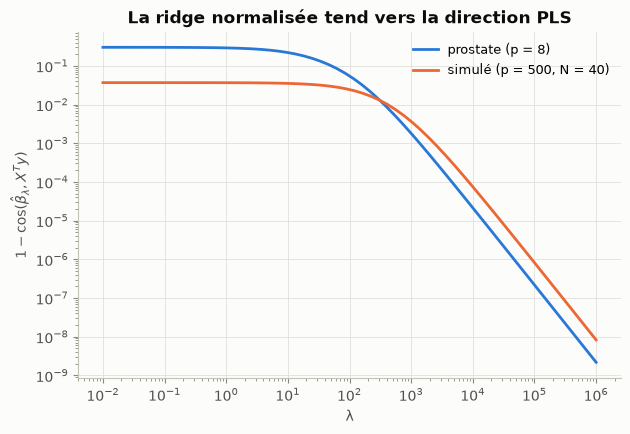

In [2]:
pro = datasets.load_prostate()
Xp = pro.drop(columns=["lpsa", "train"]).to_numpy(float)
Xp = (Xp - Xp.mean(0)) / Xp.std(0)
yp = pro["lpsa"].to_numpy() - pro["lpsa"].mean()
rng = np.random.RandomState(0)
Xh = rng.randn(40, 500)
Xh = (Xh - Xh.mean(0)) / Xh.std(0)
yh = Xh[:, :10].sum(1) + rng.randn(40)
yh -= yh.mean()

lams = np.logspace(-2, 6, 60)
fig, ax = plt.subplots(figsize=(7, 4.5))
for (X, y, name), c in zip([(Xp, yp, "prostate (p = 8)"), (Xh, yh, "simulé (p = 500, N = 40)")],
                           [BLUE, ORANGE]):
    pls = X.T @ y / np.linalg.norm(X.T @ y)
    B = g.ridge_svd(X, y, lams)
    cos = (B @ pls) / np.linalg.norm(B, axis=1)
    ax.loglog(lams, 1 - cos, color=c, label=name)
ax.set_xlabel("λ")
ax.set_ylabel(r"$1 - \cos(\hat\beta_\lambda, X^T y)$")
ax.set_title("La ridge normalisée tend vers la direction PLS")
ax.legend()
plt.show()

La distance angulaire décroît vers 0 comme $1/\lambda^2$ pour $\lambda$ grand (pente
$-2$ en log-log : $1-\cos\theta\approx\theta^2/2$ et l'angle $\theta$ est en $O(1/\lambda)$).

> **À retenir.** Les deux extrémités du chemin ridge sont la solution des moindres
> carrés de norme minimale ($\lambda\to 0$, exercice 18.7) et, à normalisation près,
> la direction PLS $\mathbf X^Ty$ ($\lambda\to\infty$).

## Exercice 18.2 : Centroïdes réduits et lasso

**Énoncé (reformulé).** Modèle de Bayes naïf gaussien : les variables
$j = 1,\dots,p$ sont indépendantes dans chaque classe $k = 1,\dots,K$, et pour
$i\in C_k$ (les $N_k$ indices de la classe $k$),
$x_{ij}\sim\mathcal N(\mu_j+\mu_{jk},\sigma_j^2)$ avec $\sum_k\mu_{jk} = 0$. On prend
$\hat\sigma_j = s_j$ (écart-type intra-classe poolé) et l'on considère le problème de
type lasso (éq. (18.55))
$$\min_{\{\mu_j,\mu_{jk}\}}\ \frac12\sum_{j=1}^p\sum_{k=1}^K\sum_{i\in C_k}\frac{(x_{ij}-\mu_j-\mu_{jk})^2}{s_j^2} + \lambda\sqrt{N_k}\sum_{j=1}^p\sum_{k=1}^K\frac{|\mu_{jk}|}{s_j}.$$
Montrer que la solution coïncide avec les centroïdes réduits (18.5), avec $s_0 = 0$ et
$m_k^2 = 1/N_k$ au lieu de $1/N_k - 1/N$.

**Rappel : le lasso à une variable.** Pour $a\in\mathbb R$ et $t\ge0$, la fonction
$h(\mu) = \frac12(a-\mu)^2 + t|\mu|$ est minimale en $\hat\mu = \operatorname{sign}(a)(|a|-t)_+$
(seuillage doux). *Preuve par cas* :

- sur $\mu > 0$, $h$ est dérivable, $h'(\mu) = \mu - a + t$, nulle en $\mu = a - t$, ce
  qui n'est admissible que si $a > t$ ;
- sur $\mu < 0$, $h'(\mu) = \mu - a - t$, nulle en $\mu = a + t$, admissible seulement si $a < -t$ ;
- si $|a|\le t$, $h$ est décroissante sur $]-\infty,0]$ et croissante sur $[0,\infty[$
  (signes de $h'$ ci-dessus), donc le minimum est en $\mu = 0$.

$h$ étant strictement convexe, ce minimum est unique.

**Solution.**

*Étape 1 : séparation.* Le critère est une somme de termes ne faisant intervenir que
les paramètres d'une variable $j$ : on peut minimiser variable par variable. On fixe
$j$ et l'on note $\bar x_{kj}$ la moyenne de la classe $k$ et $\bar x_j$ la moyenne globale.

*Étape 2 : le niveau commun $\mu_j$.* Comme dans les centroïdes réduits (18.4)-(18.7),
où l'on rétrécit les centroïdes de classe **vers le centroïde global**, on fixe
$\hat\mu_j = \bar x_j$ (c'est l'estimateur du maximum de vraisemblance de $\mu_j$ quand
$\lambda = 0$ et que la contrainte s'écrit $\sum_kN_k\mu_{jk} = 0$).

*Étape 3 : décomposition de König-Huygens.* Pour $\mu$ réel,
$$\sum_{i\in C_k}(x_{ij}-\bar x_j-\mu)^2 = \sum_{i\in C_k}(x_{ij}-\bar x_{kj})^2 + N_k(\bar x_{kj}-\bar x_j-\mu)^2,$$
car le terme croisé $2(\bar x_{kj}-\bar x_j-\mu)\sum_{i\in C_k}(x_{ij}-\bar x_{kj})$ est nul.
Le premier terme ne dépend pas de $\mu$. Pour chaque classe $k$, il reste donc à minimiser
$$\frac{N_k}{2s_j^2}(a_{kj}-\mu_{jk})^2 + \frac{\lambda\sqrt{N_k}}{s_j}|\mu_{jk}|,\qquad a_{kj} = \bar x_{kj}-\bar x_j .$$

*Étape 4 : seuillage doux.* En divisant par $N_k/s_j^2 > 0$, on obtient
$\frac12(a_{kj}-\mu_{jk})^2 + \frac{\lambda s_j}{\sqrt{N_k}}|\mu_{jk}|$, donc d'après le rappel
$$\hat\mu_{jk} = \operatorname{sign}(a_{kj})\Big(|a_{kj}| - \frac{\lambda s_j}{\sqrt{N_k}}\Big)_+ .$$
Posons $m_k = 1/\sqrt{N_k}$ et $d_{kj} = a_{kj}/(m_ks_j)$, c'est-à-dire (18.4) avec $s_0 = 0$.
En divisant par $m_ks_j > 0$ :
$$\frac{\hat\mu_{jk}}{m_ks_j} = \operatorname{sign}(d_{kj})\big(|d_{kj}| - \lambda\big)_+ = d'_{kj}\quad\text{avec }\Delta = \lambda,$$
et le centroïde estimé de la classe $k$ est $\hat\mu_j + \hat\mu_{jk} = \bar x_j + m_ks_jd'_{kj}$ :
c'est exactement (18.7). $\square$